# Preparing Metadata

This notebook builds the label table of the project: one row per symbol saying what it is (stock or ETF), where it is listed, its NASDAQ tier and its sector. The chapters use it to group symbols.

- **Inputs:**
  - `data/symbols_valid_meta.csv` (Kaggle): one row per stock/ETF of the price dataset.
  - `data/nasdaqlisted.txt` (NASDAQ Trader symbol directory): official NASDAQ market category and financial status.
  - Yahoo Finance (`yfinance`): sector and industry, cached in `data/yfinance_profiles.csv`.
- **Output:** `data_processed/metadata_clean.parquet`, the only version of the metadata; every later notebook reads it.

**Policy:** existing values are never overwritten, missing values are only filled from a reliable source, and a value that can't be checked stays missing.

**Contents**
1. Setup
2. Loading the metadata
3. Market category and financial status
4. NASDAQ-listed symbols
5. Sector and industry
6. Export

## 1. Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from src.utils.loading_data import load_nasdaq_metadata
from src.utils.metadata_enrich import (
    add_readable_labels,
    add_sector_industry,
    drop_cqs_symbol,
    enrich_market_category_and_fin_status,
    exchange_missing_breakdown,
    fetch_yfinance_profiles,
    load_nasdaq_symbol_directory,
    missing_values_meta,
    sector_coverage,
)

DATA_DIR = Path("data")
RAW_METADATA = DATA_DIR / "symbols_valid_meta.csv"
NASDAQ_DIRECTORY = DATA_DIR / "nasdaqlisted.txt"
YF_PROFILES_CACHE = DATA_DIR / "yfinance_profiles.csv"

PROCESSED_DIR = Path("data_processed")

sns.set_theme(style="whitegrid", font_scale=1.1)

## 2. Loading the metadata

`load_nasdaq_metadata` reads everything as text, trims spaces, turns `Y/N` columns into booleans, makes `round_lot_size` numeric, turns empty cells into missing values and renames the columns to snake_case.

In [2]:
meta = load_nasdaq_metadata(RAW_METADATA)
meta = drop_cqs_symbol(meta)  # not needed downstream

print(f"{len(meta)} symbols: {(~meta['etf']).sum()} stocks, {meta['etf'].sum()} ETFs")
meta.head()

8049 symbols: 5884 stocks, 2165 ETFs


,nasdaq_traded,symbol,security_name,listing_exchange,market_category,etf,round_lot_size,test_issue,financial_status,nasdaq_symbol,nextshares
0,True,A,"Agilent Technologies, Inc. Common Stock",N,NaN,False,100.0,False,NaN,A,False
1,True,AA,Alcoa Corporation Common Stock,N,NaN,False,100.0,False,NaN,AA,False
2,True,AAAU,Perth Mint Physical Gold ETF,P,NaN,True,100.0,False,NaN,AAAU,False
3,True,AACG,ATA Creativity Global - American Depositary Sh...,Q,G,False,100.0,False,N,AACG,False
4,True,AADR,AdvisorShares Dorsey Wright ADR ETF,P,NaN,True,100.0,False,NaN,AADR,False


## 3. Market category and financial status

### 3.1 Missing values

In [3]:
missing_values_meta(meta)

,missing_count,missing_percentage
nasdaq_traded,0,0.00
symbol,0,0.00
security_name,0,0.00
listing_exchange,0,0.00
market_category,4666,57.97
etf,0,0.00
round_lot_size,0,0.00
test_issue,0,0.00
financial_status,4666,57.97
nasdaq_symbol,0,0.00


Only `market_category` and `financial_status` have missing values, and both are missing for the same symbols.

### 3.2 Filling from the NASDAQ symbol directory

The official NASDAQ directory is joined on the symbol. Only missing values are filled; existing values are kept.

In [4]:
nasdaq_dir = load_nasdaq_symbol_directory(NASDAQ_DIRECTORY)

missing_before = meta["market_category"].isna().sum()
meta = enrich_market_category_and_fin_status(meta, nasdaq_dir)
meta = add_readable_labels(meta)
missing_after = meta["market_category"].isna().sum()

print(f"Missing market_category: {missing_before} -> {missing_after} ({missing_before - missing_after} filled)")

Missing market_category: 4666 -> 4564 (102 filled)


### 3.3 Why the rest stays missing

Both fields are NASDAQ concepts: they only exist for symbols **listed on NASDAQ**. A symbol listed on the NYSE has no NASDAQ tier, so for those the value doesn't apply rather than being missing.

In [5]:
exchange_missing_breakdown(meta, by="listing_exchange_label")

,rows,mc_missing,fs_missing
listing_exchange_label,,,
NASDAQ,3383,0,0
NYSE,2520,2456,2456
NYSE Arca,1542,1522,1522
Cboe BZX (BATS),351,346,346
NYSE American,253,240,240


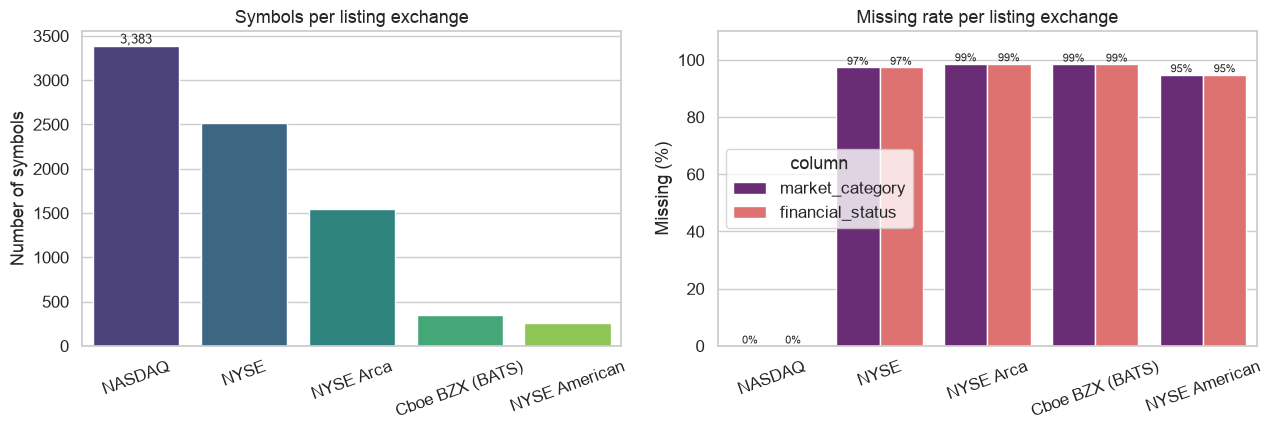

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

counts = meta["listing_exchange_label"].value_counts()
sns.barplot(x=counts.index, y=counts.values, hue=counts.index, legend=False, palette="viridis", ax=axes[0])
axes[0].bar_label(axes[0].containers[0], fmt="{:,.0f}", fontsize=9)
axes[0].set(title="Symbols per listing exchange", xlabel="", ylabel="Number of symbols")

missing_rates = (
    meta.groupby("listing_exchange_label")[["market_category", "financial_status"]]
    .apply(lambda x: x.isna().mean() * 100)
    .reindex(counts.index)
    .reset_index()
    .melt(id_vars="listing_exchange_label", var_name="column", value_name="missing_%")
)
sns.barplot(data=missing_rates, x="listing_exchange_label", y="missing_%", hue="column", palette="magma", ax=axes[1])
axes[1].set(title="Missing rate per listing exchange", xlabel="", ylabel="Missing (%)", ylim=(0, 110))
for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.0f%%", fontsize=8)

for ax in axes:
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

## 4. NASDAQ-listed symbols

Careful: the letter **Q** has two meanings in this data. `listing_exchange == "Q"` means *listed on NASDAQ*, while `market_category == "Q"` means *NASDAQ Global Select tier*. To avoid mixing them up, this section uses the readable label columns.

- **Market category** (listing tier, strictest first): Global Select → Global Market → Capital Market (smallest companies).
- **Financial status:** Normal, or a combination of Deficient (fails listing rules), Delinquent (late filings) and Bankrupt.

In [7]:
nasdaq = meta[meta["listing_exchange_label"] == "NASDAQ"]
print(f"NASDAQ-listed symbols: {len(nasdaq)}")

NASDAQ-listed symbols: 3383


### 4.1 Market categories

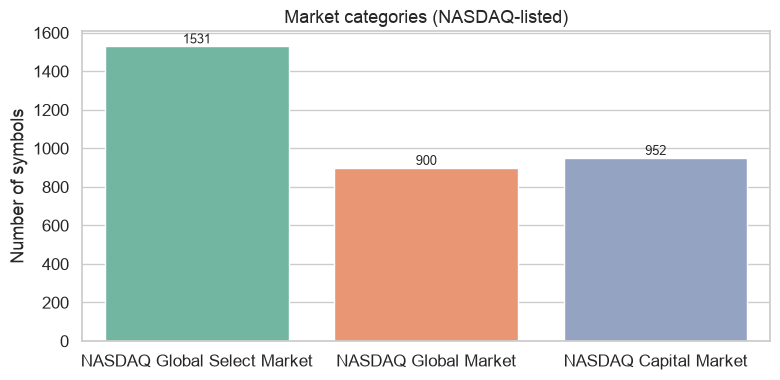

In [8]:
order = ["NASDAQ Global Select Market", "NASDAQ Global Market", "NASDAQ Capital Market"]

plt.figure(figsize=(8, 4))
ax = sns.countplot(data=nasdaq, x="market_category_label", order=order,
                   hue="market_category_label", hue_order=order, legend=False, palette="Set2")
for container in ax.containers:
    ax.bar_label(container, fontsize=9)
ax.set(title="Market categories (NASDAQ-listed)", xlabel="", ylabel="Number of symbols")
plt.tight_layout()
plt.show()

### 4.2 Financial status

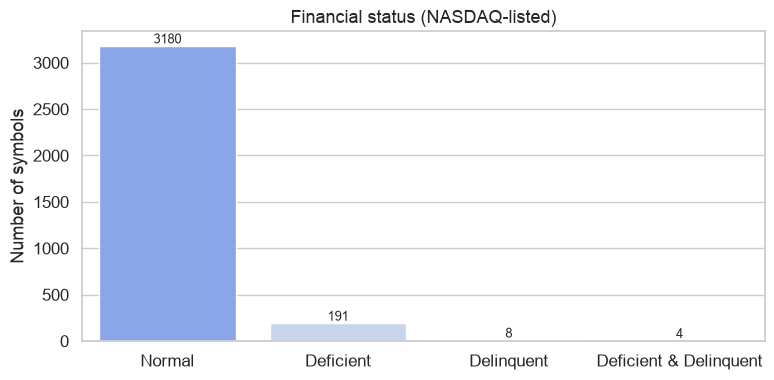

financial_status_label,Deficient,Deficient & Delinquent,Delinquent,Normal
market_category_label,,,,
NASDAQ Capital Market,164,4,3,781
NASDAQ Global Market,16,0,2,882
NASDAQ Global Select Market,11,0,3,1517


In [9]:
status = nasdaq.dropna(subset=["financial_status_label"])

plt.figure(figsize=(8, 4))
ax = sns.countplot(data=status, x="financial_status_label",
                   hue="financial_status_label", legend=False, palette="coolwarm")
for container in ax.containers:
    ax.bar_label(container, fontsize=9)
ax.set(title="Financial status (NASDAQ-listed)", xlabel="", ylabel="Number of symbols")
plt.tight_layout()
plt.show()

pd.crosstab(status["market_category_label"], status["financial_status_label"])

Almost every symbol has a "Normal" financial status, so this variable can't separate groups and is **not used** in the analysis. The market category is kept: it is the basis of Chapter 3.

## 5. Sector and industry

Sectors and industries come from Yahoo Finance (`yfinance`), looked up for every **stock** (ETFs have no single sector).

### 5.1 Fetch the Yahoo profiles

In [10]:
stock_symbols = meta.loc[~meta["etf"], "symbol"].tolist()
profiles = fetch_yfinance_profiles(stock_symbols, YF_PROFILES_CACHE)

print(f"Lookup dates: {profiles['fetched_on'].min()} → {profiles['fetched_on'].max()}")
profiles["status"].str.split(":").str[0].value_counts()

5884 symbols already cached, 0 to fetch


Fetching Yahoo profiles: 0it [00:00, ?it/s]

Lookup dates: 2026-11-15 → 2026-11-15


status
ok         3652
no data    2232
Name: count, dtype: int64

### 5.2 Check that each ticker is still the same company

Since 2020, some companies were delisted and some tickers were reused by other companies. A reused ticker would get the *new* company's sector. So a Yahoo sector is only kept when Yahoo's company name shares at least one significant word with the 2020 `security_name` (ignoring words like "Inc", "Corp", "Common Stock"). Otherwise, Sector and Industry stay missing.

In [11]:
meta = add_sector_industry(meta, profiles)

stocks = meta[~meta["etf"]]
mismatched = stocks[stocks["yf_name"].notna() & ~stocks["yf_name_match"]]
print(f"Yahoo profile found:        {stocks['yf_name'].notna().sum()} stocks")
print(f"Name mismatch (sector dropped): {len(mismatched)} stocks\n")

mismatched[["symbol", "security_name", "yf_name"]].head(20)

Yahoo profile found:        3652 stocks
Name mismatch (sector dropped): 206 stocks



,symbol,security_name,yf_name
49,ACH,Aluminum Corporation of China Limited American...,"Accendra Health, Inc."
188,AI,Arlington Asset Investment Corp Class A (new),"C3.ai, Inc."
229,AKTS,"Akoustis Technologies, Inc. - Common Stock","Aktis Oncology, Inc."
289,AMCI,AMCI Acquisition Corp. - Class A Common Stock,AMC Robotics Corporation
329,AMTD,TD Ameritrade Holding Corporation - Common Stock,AMTD IDEA Group
334,AMX,"America Movil, S.A.B. de C.V. American Deposit...","América Móvil, S.A.B. de C.V."
358,ANY,Sphere 3D Corp. - Common Shares,DarkHorse Technologies Inc
369,APA,Apache Corporation Common Stock,APA Corporation
490,AT,Atlantic Power Corporation Ordinary Shares (Ca...,Defiance Robotics Actuators ETF
502,ATI,Allegheny Technologies Incorporated Common Stock,ATI Inc.


### 5.3 Coverage

How many stocks end up with a sector, per listing exchange.

In [12]:
sector_coverage(meta)

,stocks,with_sector,coverage_%
listing_exchange_label,,,
Cboe BZX (BATS),17,1,5.9
NASDAQ,2988,1613,54.0
NYSE,2520,1587,63.0
NYSE American,252,153,60.7
NYSE Arca,107,3,2.8
Total,5884,3357,57.1


### 5.4 Sector distribution

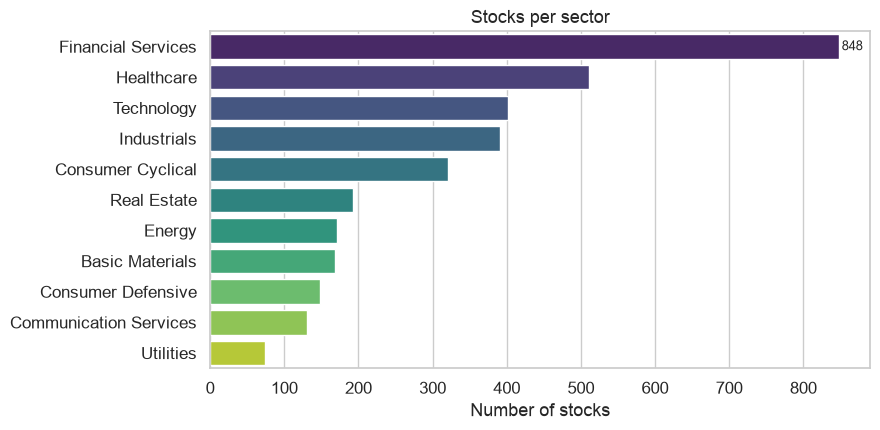

In [13]:
sector_counts = meta["Sector"].value_counts()

plt.figure(figsize=(9, 4.5))
ax = sns.barplot(x=sector_counts.values, y=sector_counts.index, hue=sector_counts.index, legend=False, palette="viridis")
ax.bar_label(ax.containers[0], fontsize=9, padding=2)
ax.set(title="Stocks per sector", xlabel="Number of stocks", ylabel="")
plt.tight_layout()
plt.show()

## 6. Export

`data_processed/metadata_clean.parquet`, used by every later notebook.

In [14]:
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
meta.to_parquet(PROCESSED_DIR / "metadata_clean.parquet", index=False)

print(f"Saved {len(meta)} symbols with columns:")
print(list(meta.columns))

Saved 8049 symbols with columns:
['nasdaq_traded', 'symbol', 'security_name', 'listing_exchange', 'market_category', 'etf', 'round_lot_size', 'test_issue', 'financial_status', 'nasdaq_symbol', 'nextshares', 'listing_exchange_label', 'market_category_label', 'financial_status_label', 'yf_name', 'Sector', 'Industry', 'fetched_on', 'yf_name_match']
